Libraries ready!
Dataset loaded: (1170, 6)
['Date', 'Children apprehended and placed in CBP custody', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']
Missing columns: []
Invalid dates: 450
First date: 2023-01-12 00:00:00
Last date: 2025-12-21 00:00:00
Duplicate dates: 0
Missing values:


Date                                              0
Children apprehended and placed in CBP custody    0
Children in CBP custody                           0
Children transferred out of CBP custody           0
Children in HHS Care                              0
Children discharged from HHS Care                 0
dtype: int64

Data types:


Date                                              datetime64[us]
Children apprehended and placed in CBP custody           float64
Children in CBP custody                                  float64
Children transferred out of CBP custody                  float64
Children in HHS Care                                       int64
Children discharged from HHS Care                        float64
dtype: object

,Date,Children apprehended and placed in CBP custody,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720,720.000000,720.000000,720.000000,720.000000,720.000000
mean,2024-07-06 05:30:00,93.523611,171.494444,128.668056,6061.275000,173.406944
min,2023-01-12 00:00:00,0.000000,7.000000,0.000000,1972.000000,0.000000
25%,2023-10-16 18:00:00,12.000000,36.000000,14.000000,2467.750000,19.750000
50%,2024-07-05 12:00:00,99.000000,193.000000,157.000000,6406.500000,181.000000
75%,2025-03-25 06:00:00,147.250000,263.250000,199.250000,8010.250000,267.000000
max,2025-12-21 00:00:00,333.000000,531.000000,440.000000,11516.000000,505.000000
std,NaN,72.646625,126.354965,97.322012,2833.070109,125.702841


Negative values by column:


Children apprehended and placed in CBP custody    0
Children in CBP custody                           0
Children transferred out of CBP custody           0
Children in HHS Care                              0
Children discharged from HHS Care                 0
dtype: int64

Transfer flags: 86
Discharge flags: 0
Expected calendar days: 1075
Missing calendar dates: 355
DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26', '2023-01-27', '2023-01-28',
               '2023-02-03', '2023-02-04', '2023-02-10', '2023-02-11',
               '2023-02-17', '2023-02-18', '2023-02-19', '2023-02-24'],
              dtype='datetime64[us]', freq=None)


,count,mean,std,min,25%,50%,75%,max
Children apprehended and placed in CBP custody,720.0,93.523611,72.646625,0.0,12.00,99.0,147.25,333.0
Children in CBP custody,720.0,171.494444,126.354965,7.0,36.00,193.0,263.25,531.0
Children transferred out of CBP custody,720.0,128.668056,97.322012,0.0,14.00,157.0,199.25,440.0
Children in HHS Care,720.0,6061.275000,2833.070109,1972.0,2467.75,6406.5,8010.25,11516.0
Children discharged from HHS Care,720.0,173.406944,125.702841,0.0,19.75,181.0,267.00,505.0


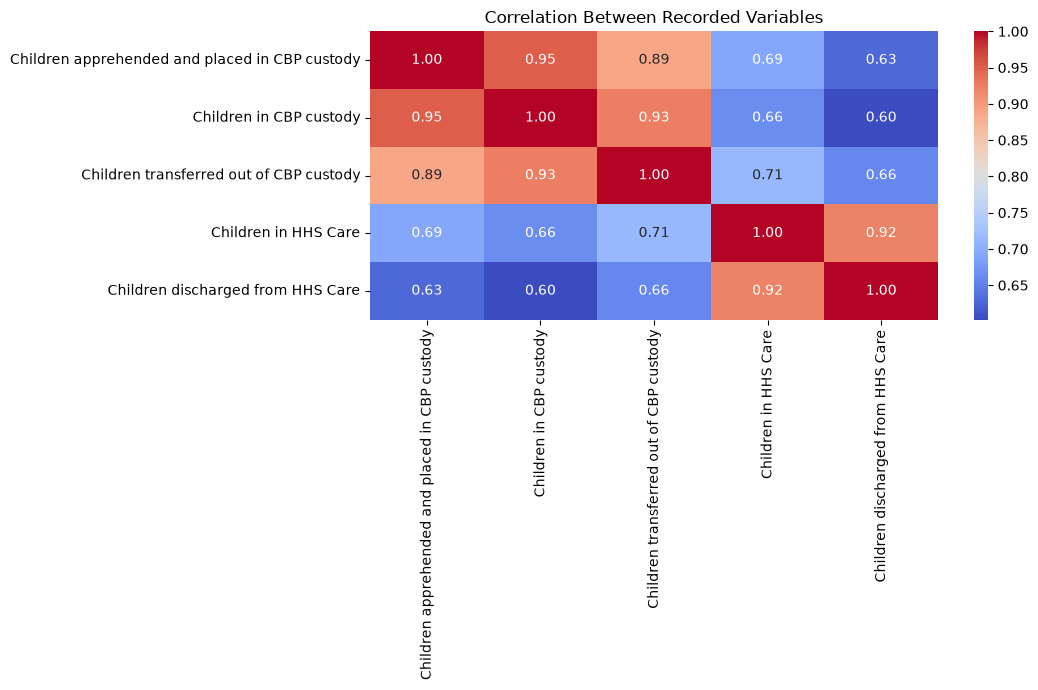

,Value
Latest Total System Load,2502.000000
Average Daily System Load,6232.769444
Maximum Recorded System Load,11762.000000
Average Net HHS Intake,-44.738889
Positive Net Intake Days,238.000000
Negative Net Intake Days,475.000000


Discharge Offset Ratio: 1.3477078183525653
Gaps interpolated: 355
Usable observations: 1075
Training observations: 860
Testing observations: 215
Training ends: 2025-05-20 00:00:00
Testing begins: 2025-05-21 00:00:00
Baseline MAE: 229.36
Baseline RMSE: 284.48
ARIMA MAE: 245.12
ARIMA RMSE: 301.98


,Model,MAE,RMSE
0,Naive baseline,229.36,284.48
1,"ARIMA(1,1,1)",245.12,301.98


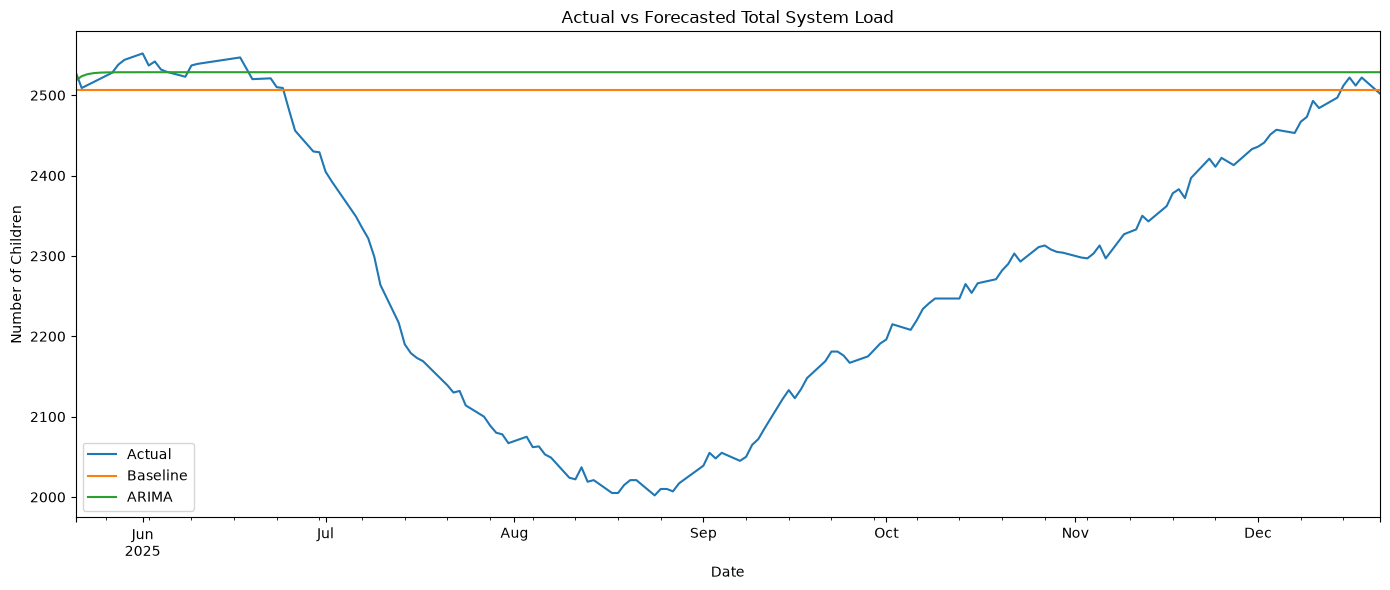

,Date,Forecasted System Load
0,2025-12-22,2498.572222
1,2025-12-23,2496.948906
2,2025-12-24,2496.180140
3,2025-12-25,2495.816070
4,2025-12-26,2495.643655
5,2025-12-27,2495.562003
6,2025-12-28,2495.523335
7,2025-12-29,2495.505022
8,2025-12-30,2495.496350
9,2025-12-31,2495.492243


df: (720, 17) | future_df: (30, 2)
Saved!


In [2]:

# # System Capacity & Care Load Analytics: EDA, KPIs and Forecasting
 
# %% [markdown]
# ## 1. Import libraries
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
 
pd.set_option("display.max_columns", None)
print("Libraries ready!")
 
# %% [markdown]
# ## 2. Load the dataset
# %%
df = pd.read_csv("../data/HHS_Unaccompanied_Alien_Children_Program.csv")
print("Dataset loaded:", df.shape)
df.head()
 
# %% [markdown]
# ## 3. Clean column names
# %%
COLS = [
    "Children apprehended and placed in CBP custody",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care",
]
 
df.columns = (
    df.columns
      .str.replace("\ufeff", "", regex=False)   # hidden BOM character
      .str.replace("*", "", regex=False)        # footnote asterisk
      .str.replace(r"\s+", " ", regex=True)     # extra spaces / line breaks
      .str.strip()
)
 
# If the file has 6 columns in the expected order, set exact names by position
if df.shape[1] == 6:
    df.columns = ["Date"] + COLS
 
print(df.columns.tolist())
 
missing_cols = [c for c in ["Date"] + COLS if c not in df.columns]
print("Missing columns:", missing_cols)
 
# %% [markdown]
# ## 4. Dates, sorting, duplicates
# %%
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Invalid dates:", df["Date"].isna().sum())
 
df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)
 
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
print("Duplicate dates:", df["Date"].duplicated().sum())
 
# %% [markdown]
# ## 5. Numeric conversion and missing values
# %%
count_cols = COLS
 
for col in count_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )
 
print("Missing values:")
display(df.isnull().sum())
print("Data types:")
display(df.dtypes)
display(df.describe(include="all"))
 
# %% [markdown]
# ## 6. Validation flags
# %%
print("Negative values by column:")
display(df[count_cols].lt(0).sum())
 
df["Flag_Transfer_Exceeds_CBP"] = (
    df["Children transferred out of CBP custody"] > df["Children in CBP custody"]
)
df["Flag_Discharge_Exceeds_HHS"] = (
    df["Children discharged from HHS Care"] > df["Children in HHS Care"]
)
 
print("Transfer flags:", df["Flag_Transfer_Exceeds_CBP"].sum())
print("Discharge flags:", df["Flag_Discharge_Exceeds_HHS"].sum())
 
# %% [markdown]
# ## 7. Missing calendar dates
# %%
all_dates = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
missing_dates = all_dates.difference(df["Date"])
 
print("Expected calendar days:", len(all_dates))
print("Missing calendar dates:", len(missing_dates))
print(missing_dates[:20])
 
# %% [markdown]
# ## 8. Exploratory Data Analysis
# %%
display(df[count_cols].describe().T)
 
# %%
fig = px.line(
    df, x="Date",
    y=["Children in CBP custody", "Children in HHS Care"],
    title="Daily Care Load: CBP vs HHS",
    labels={"value": "Number of Children", "Date": "Date", "variable": "Care Stage"}
)
fig.show()
 
# %%
fig = px.line(
    df, x="Date",
    y=["Children apprehended and placed in CBP custody",
       "Children discharged from HHS Care"],
    title="Daily Intake vs Discharges",
    labels={"value": "Number of Children", "Date": "Date", "variable": "Measure"}
)
fig.show()
 
# %%
monthly = (
    df.set_index("Date")[count_cols]
      .resample("MS").mean()
      .reset_index()
)
fig = px.line(
    monthly, x="Date",
    y=["Children in CBP custody", "Children in HHS Care"],
    title="Average Monthly Care Load",
    labels={"value": "Average Number of Children", "variable": "Care Stage"}
)
fig.show()
 
# %%
plt.figure(figsize=(11, 7))
sns.heatmap(df[count_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Recorded Variables")
plt.tight_layout()
plt.show()
 
# %% [markdown]
# ## 9. Feature engineering and KPIs
# %%
df["Total System Load"] = df["Children in CBP custody"] + df["Children in HHS Care"]
df["Net HHS Intake"] = (
    df["Children transferred out of CBP custody"] - df["Children discharged from HHS Care"]
)
df["Daily System Load Change"] = df["Total System Load"].diff()
df["Care Load Growth Rate (%)"] = df["Total System Load"].pct_change(fill_method=None) * 100
df["7-Day Average"] = df["Total System Load"].rolling(7, min_periods=7).mean()
df["14-Day Average"] = df["Total System Load"].rolling(14, min_periods=14).mean()
 
df["Positive HHS Intake"] = (df["Net HHS Intake"] > 0).astype(int)
df["Positive Intake Days (7-day)"] = df["Positive HHS Intake"].rolling(7, min_periods=7).sum()
df["Sustained HHS Pressure"] = df["Positive Intake Days (7-day)"] >= 5
 
fig = px.line(
    df, x="Date",
    y=["Total System Load", "7-Day Average", "14-Day Average"],
    title="Total Care Load and Rolling Averages",
    labels={"value": "Number of Children", "variable": "Measure"}
)
fig.show()
 
# %%
total_load = df["Total System Load"].dropna()
net_intake = df["Net HHS Intake"].dropna()
 
kpis = {
    "Latest Total System Load": total_load.iloc[-1],
    "Average Daily System Load": total_load.mean(),
    "Maximum Recorded System Load": total_load.max(),
    "Average Net HHS Intake": net_intake.mean(),
    "Positive Net Intake Days": (net_intake > 0).sum(),
    "Negative Net Intake Days": (net_intake < 0).sum(),
}
display(pd.Series(kpis, name="Value").to_frame())
 
total_transfers = df["Children transferred out of CBP custody"].sum(min_count=1)
total_discharges = df["Children discharged from HHS Care"].sum(min_count=1)
discharge_offset_ratio = (
    total_discharges / total_transfers
    if pd.notna(total_transfers) and total_transfers != 0 else np.nan
)
print("Discharge Offset Ratio:", discharge_offset_ratio)
 
# %% [markdown]
# ## 10. Forecasting
# One row per date, regular daily index (gaps interpolated, document in report)
forecast_df = (
    df[["Date", "Total System Load"]]
    .dropna()
    .drop_duplicates("Date")
    .sort_values("Date")
    .set_index("Date")
    .asfreq("D")
)
n_gaps = forecast_df["Total System Load"].isna().sum()
forecast_df["Total System Load"] = forecast_df["Total System Load"].interpolate()
print("Gaps interpolated:", n_gaps)
print("Usable observations:", len(forecast_df))
 
#
split_index = int(len(forecast_df) * 0.8)
train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()
 
print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index.max())
print("Testing begins:", test.index.min())
 

# Baseline: repeat last training value
baseline_predictions = np.repeat(train["Total System Load"].iloc[-1], len(test))
 
baseline_mae = mean_absolute_error(test["Total System Load"], baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(test["Total System Load"], baseline_predictions))
print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
 
# %%
# ARIMA(1,1,1)
fitted_model = ARIMA(train["Total System Load"], order=(1, 1, 1)).fit()
predictions = fitted_model.forecast(steps=len(test))
predictions.index = test.index
 
arima_mae = mean_absolute_error(test["Total System Load"], predictions)
arima_rmse = np.sqrt(mean_squared_error(test["Total System Load"], predictions))
print("ARIMA MAE:", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))
 
# %%
results = pd.DataFrame({
    "Model": ["Naive baseline", "ARIMA(1,1,1)"],
    "MAE": [round(baseline_mae, 2), round(arima_mae, 2)],
    "RMSE": [round(baseline_rmse, 2), round(arima_rmse, 2)],
})
display(results)
 
comparison = pd.DataFrame({
    "Actual": test["Total System Load"],
    "Baseline": baseline_predictions,
    "ARIMA": predictions,
})
comparison.plot(figsize=(14, 6))
plt.title("Actual vs Forecasted Total System Load")
plt.ylabel("Number of Children")
plt.tight_layout()
plt.show()
 
# %%
# 30-day forecast: refit on all data
final_model = ARIMA(forecast_df["Total System Load"], order=(1, 1, 1)).fit()
future_forecast = final_model.forecast(steps=30)
 
future_df = pd.DataFrame({
    "Date": pd.date_range(forecast_df.index.max() + pd.Timedelta(days=1), periods=30, freq="D"),
    "Forecasted System Load": future_forecast.to_numpy(),
})
display(future_df.head(10))
 
fig = px.line(
    future_df, x="Date", y="Forecasted System Load",
    title="30-Day Total System Load Forecast",
    labels={"Forecasted System Load": "Number of Children"}
)
fig.show()
 
# %% [markdown]
# ## 11. Save outputs
# %%
df.to_csv("../data/cleaned_data.csv", index=False)
future_df.to_csv("../data/forecast_30_days.csv", index=False)
results.to_csv("../data/model_results.csv", index=False)
 
print("df:", df.shape, "| future_df:", future_df.shape)
print("Saved!")
 



In [3]:
df.to_csv("../data/cleaned_data.csv", index=False)
future_df.to_csv("../data/forecast_30_days.csv", index=False)
print("Saved!")

Saved!


In [4]:
# ---- Extra KPIs ----
df["Care Load Volatility Index"] = df["Total System Load"].rolling(7, min_periods=7).std() / df["7-Day Average"]
df["Backlog Accumulation Rate"] = df["Net HHS Intake"].rolling(7, min_periods=7).mean()

high, low = df["7-Day Average"].quantile(0.75), df["7-Day Average"].quantile(0.25)
df["Load Status"] = np.where(df["7-Day Average"] >= high, "Strain",
                     np.where(df["7-Day Average"] <= low, "Relief", "Normal"))
run_id = (df["Load Status"] != df["Load Status"].shift()).cumsum()
runs = df.groupby(run_id).agg(Status=("Load Status", "first"), Start=("Date", "min"),
                              End=("Date", "max"), Days=("Date", "count"))
strain_windows = runs[(runs["Status"] == "Strain") & (runs["Days"] >= 14)]

mid = df["Date"].min() + (df["Date"].max() - df["Date"].min()) / 2
df["Period"] = np.where(df["Date"] <= mid, "Early", "Late")

weekly = df.set_index("Date")[["Total System Load"]].resample("W").mean().reset_index()
px.line(weekly, x="Date", y="Total System Load", title="Weekly Average Total System Load",
        labels={"Total System Load": "Number of Children"}).show()

# ---- Numbers for the report ----
print("ROWS:", len(df), "| DUPLICATE DATES:", df["Date"].duplicated().sum())
print("MISSING CALENDAR DATES:", len(missing_dates), "| GAPS INTERPOLATED:", n_gaps)
print("MISSING VALUES:", df[COLS].isnull().sum().to_dict())
print("TRANSFER FLAGS:", df["Flag_Transfer_Exceeds_CBP"].sum(),
      "| DISCHARGE FLAGS:", df["Flag_Discharge_Exceeds_HHS"].sum())
print("POSITIVE / NEGATIVE NET INTAKE DAYS:", (net_intake > 0).sum(), "/", (net_intake < 0).sum())
print("\nMODEL RESULTS"); print(results.to_string(index=False))
print("\nEARLY vs LATE"); print(df.groupby("Period")[["Total System Load", "Net HHS Intake",
      "Care Load Volatility Index"]].agg(["mean", "max"]).round(1).to_string())
print("\nSTRAIN WINDOWS"); print(strain_windows.to_string())
print("\n30-DAY FORECAST: first", round(future_df.iloc[0, 1]), "| last", round(future_df.iloc[-1, 1]),
      "| min", round(future_df.iloc[:, 1].min()), "| max", round(future_df.iloc[:, 1].max()))

ROWS: 720 | DUPLICATE DATES: 0
MISSING CALENDAR DATES: 355 | GAPS INTERPOLATED: 355
MISSING VALUES: {'Children apprehended and placed in CBP custody': 0, 'Children in CBP custody': 0, 'Children transferred out of CBP custody': 0, 'Children in HHS Care': 0, 'Children discharged from HHS Care': 0}
TRANSFER FLAGS: 86 | DISCHARGE FLAGS: 0
POSITIVE / NEGATIVE NET INTAKE DAYS: 238 / 475

MODEL RESULTS
         Model    MAE   RMSE
Naive baseline 229.36 284.48
  ARIMA(1,1,1) 245.12 301.98

EARLY vs LATE
       Total System Load          Net HHS Intake        Care Load Volatility Index     
                    mean      max           mean    max                       mean  max
Period                                                                                 
Early             8615.3  11762.0          -88.3  206.0                        0.0  0.1
Late              3863.5   7016.0           -1.4  135.0                        0.0  0.1

STRAIN WINDOWS
             Status      Start        End  

In [5]:
raw = pd.read_csv("../data/HHS_Unaccompanied_Alien_Children_Program.csv")
raw.columns = ["Date"] + COLS
parsed = pd.to_datetime(raw["Date"], errors="coerce")
bad = raw[parsed.isna()]

print(len(bad), "unparsed rows")
print("First 5 raw dates:", raw["Date"].head(5).tolist())
print("Unparsed samples (first 15):", bad["Date"].head(15).tolist())
print("Unparsed samples (last 5):", bad["Date"].tail(5).tolist())
print(bad[COLS].notna().all(axis=1).sum(), "of the unparsed rows have all 5 counts filled")

450 unparsed rows
First 5 raw dates: ['December 21, 2025', 'December 18, 2025', 'December 17, 2025', 'December 16, 2025', 'December 15, 2025']
Unparsed samples (first 15): [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]
Unparsed samples (last 5): [nan, nan, nan, nan, nan]
0 of the unparsed rows have all 5 counts filled
